# Backtesting Value-at-Risk Models through Crises: Bitcoin, Ether and the S&P 500

**Question:** Value-at-Risk (VaR) is the loss a portfolio should exceed only on a given fraction of days. A 99% one-day VaR should be breached about 2–3 times a year. Banks are regulated on it, and crypto funds and exchanges set margins with it. But a VaR model is only as good as its assumptions, and crises are when those assumptions break. Which VaR models give the right number of breaches, at the right times, and with the right size of loss, through the COVID crash, the 2022 crypto collapses and the 2024–2025 shocks?

This notebook:

1. Builds five standard one-day VaR models: historical simulation, a normal model, RiskMetrics EWMA, filtered historical simulation, and GARCH(1,1) with Student-t errors. Each is re-estimated every day using only past data.
2. Runs them on Bitcoin, Ether and the S&P 500 from January 2019 to September 2026.
3. Backtests 99% and 95% VaR with the Kupiec (1995) test for the *number* of exceptions and the Christoffersen (1998) tests for their *clustering*.
4. Applies the Basel traffic-light test over rolling 250-day windows, as a regulator would.
5. Zooms in on six crisis episodes, including the COVID crash day by day.
6. Checks 97.5% expected shortfall, the measure Basel's FRTB uses in place of VaR, on the days the tail is reached.

*Inspired by WQU MScFE 560, Module 6 (Model Failure and Crises): models, their inputs and assumptions, and why they fail in crises. Builds on Module 2's finding that returns are not Gaussian and on the GARCH model of the Volatility Targeting notebook.*

In [1]:
import subprocess
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
from scipy.optimize import minimize
from scipy.signal import lfilter
from scipy.special import gammaln, xlogy

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})
WINDOW = 500           # estimation window (observations) for every model except the 250-day ones
EVAL_START = "2019-01-01"
ES_LEVEL = 0.025       # expected shortfall at 97.5%, the Basel FRTB standard
LEVELS = [0.01, ES_LEVEL, 0.05]   # VaR tail probabilities computed: 99%, 97.5% (defines the ES tail) and 95%
BT_LEVELS = [0.01, 0.05]          # VaR levels backtested
MODELS = ["Historical 250d", "Normal 250d", "EWMA normal", "Filtered HS", "GARCH-t"]

## 1. Data

* **BTC/USDT and ETH/USDT** daily closes from Binance since they were listed on 2017-08-17, downloaded with `src/data.py`. Crypto trades every day.
* **S&P 500** daily closes from FRED, which serves the last ten years (from October 2016). It trades on business days only.

The backtest starts on 2019-01-01. That leaves at least 500 returns of history for the first forecast of every model, and the test period includes the COVID crash of March 2020.

In [2]:
SRC = next(p / "src" for p in Path.cwd().resolve().parents if (p / "src" / "data.py").exists())
SYMBOLS = ["BTC/USDT", "ETH/USDT"]
START, END = "2017-08-17", "2026-10-01"   # Binance listed BTC/USDT and ETH/USDT on 2017-08-17

cmd = [sys.executable, str(SRC / "data.py"), *SYMBOLS, "--since", START, "--until", END, "--full"]
result = subprocess.run(cmd, capture_output=True, text=True)
print("Crypto: downloaded from Binance" if result.returncode == 0 else "Crypto: download failed, using existing CSVs in src/data")

sp_path = SRC / "data" / "FRED_SP500.csv"
try:
    pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500", index_col=0).to_csv(sp_path)
    print("S&P 500: downloaded from FRED")
except Exception as e:
    print(f"S&P 500: download failed ({type(e).__name__}), using existing CSV in src/data")


def load_close(symbol):
    path = SRC / "data" / f"BINANCE_{symbol.replace('/', '-')}_1d.csv"
    return pd.read_csv(path, parse_dates=["Date"], index_col="Date")["Close"]


prices = {"BTC": load_close("BTC/USDT"), "ETH": load_close("ETH/USDT"),
          "S&P 500": pd.read_csv(sp_path, index_col=0, parse_dates=True).iloc[:, 0].dropna()}
# all available history (FRED serves the S&P 500 from October 2016) up to END
returns = {k: v.loc[:END].loc[lambda s: s.index < END].pct_change().dropna() for k, v in prices.items()}
for k, r in returns.items():
    print(f"{k:8s}: {len(r)} daily returns {r.index[0].date()} → {r.index[-1].date()}; "
          f"backtest from {EVAL_START}: {len(r.loc[EVAL_START:])} days")

Crypto: downloaded from Binance


S&P 500: downloaded from FRED
BTC     : 3331 daily returns 2017-08-18 → 2026-09-30; backtest from 2019-01-01: 2830 days
ETH     : 3331 daily returns 2017-08-18 → 2026-09-30; backtest from 2019-01-01: 2830 days
S&P 500 : 2511 daily returns 2016-10-04 → 2026-09-30; backtest from 2019-01-01: 1947 days


## 2. Five VaR models

VaR at tail probability $\alpha$ is the loss that is exceeded with probability $\alpha$ the next day: $P(L_{t} > \text{VaR}_t) = \alpha$. An **exception** is a day when the actual loss is larger than the VaR forecast made the evening before. The models differ in what they assume about the distribution of tomorrow's return:

| Model | Volatility | Shape of the distribution |
|---|---|---|
| **Historical 250d** | implicit: last 250 days, equally weighted | empirical quantile of the last 250 returns |
| **Normal 250d** | standard deviation of the last 250 days | normal |
| **EWMA normal** (RiskMetrics) | exponentially weighted, λ = 0.94 | normal |
| **Filtered HS** (Barone-Adesi et al., 1999) | EWMA, λ = 0.94 | empirical quantile of the last 500 standardized returns $r_t/\sigma_t$ |
| **GARCH-t** | GARCH(1,1), re-estimated every 21 days on the last 500 days | Student-t, with degrees of freedom estimated |

Two of these choices matter most. The first is whether volatility can **react quickly**: EWMA, Filtered HS and GARCH can, while the 250-day models cannot (Pritsker, 2006). The second is whether the tails are **fat**: Historical, Filtered HS and GARCH-t allow fat tails, while the normal models do not. Each model also produces a 97.5% VaR and a 97.5% expected shortfall (ES), used in Section 6.

The loop below re-estimates every model on each day of the test period using only data up to the previous close. That is about 7,600 forecasts per model.

In [3]:
def garch_variance(params, eps, h0):
    """GARCH(1,1) one-step-ahead variances: h[t] is the forecast for day t made at the close of t-1."""
    omega, alpha, beta = params[:3]
    x = omega + alpha * eps**2
    return np.concatenate([[h0], lfilter([1.0], [1.0, -beta], x, zi=[beta * h0])[0]])


def neg_loglik(params, eps):
    omega, alpha, beta, nu = params
    if alpha + beta >= 0.9999:
        return 1e10
    h = garch_variance(params, eps, eps.var())[:-1]
    const = gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
    return -np.sum(const - 0.5 * np.log(h) - (nu + 1) / 2 * np.log1p(eps**2 / (h * (nu - 2))))


def fit_garch(eps, start):
    v = eps.var()
    res = minimize(neg_loglik, start if start is not None else [0.05 * v, 0.10, 0.85, 5.0], args=(eps,),
                   method="L-BFGS-B", bounds=[(1e-10, None), (1e-6, 0.5), (0.3, 0.9999), (2.1, 50.0)])
    return res.x


def t_quantile_es(alpha, nu):
    """Left-tail quantile and expected shortfall (both as positive numbers) of a unit-variance Student-t."""
    scale = np.sqrt((nu - 2) / nu)
    q = stats.t.ppf(alpha, nu)
    es = stats.t.pdf(q, nu) / alpha * (nu + q**2) / (nu - 1)
    return -q * scale, es * scale


def vcol(lvl):
    return f"VaR{(1 - lvl) * 100:g}"


def var_forecasts(r, refit_every=21):
    """One-day-ahead VaR (positive loss) at each level in LEVELS, and 97.5% ES, for each model.

    Every forecast for day t uses returns up to day t-1 only.
    """
    x = r.values
    n = len(x)
    idx = r.index
    eval_pos = np.searchsorted(idx, pd.Timestamp(EVAL_START))
    assert eval_pos >= WINDOW, f"need {WINDOW} returns before {EVAL_START}, have {eval_pos}"
    out = {m: {lvl: np.full(n, np.nan) for lvl in LEVELS + ["ES"]} for m in MODELS}
    sigma = {m: np.full(n, np.nan) for m in MODELS}

    # EWMA variance, λ = 0.94 (RiskMetrics), seeded with the first 30 days
    lam = 0.94
    ew = np.empty(n)
    ew[0] = x[:30].var()
    for t in range(1, n):
        ew[t] = lam * ew[t - 1] + (1 - lam) * x[t - 1] ** 2
    ew_sd = np.sqrt(ew)
    z = x / ew_sd                                   # EWMA-standardized residuals, for filtered HS

    params = None
    for t in range(eval_pos, n):
        past = x[t - 250:t]
        # 1. historical simulation: empirical quantile of the last 250 returns
        for lvl in LEVELS:
            out["Historical 250d"][lvl][t] = -np.quantile(past, lvl)
        q = np.quantile(past, ES_LEVEL)
        out["Historical 250d"]["ES"][t] = -past[past <= q].mean()
        sigma["Historical 250d"][t] = past.std()
        # 2. normal with 250-day volatility (zero mean)
        s = past.std()
        for lvl in LEVELS:
            out["Normal 250d"][lvl][t] = -s * stats.norm.ppf(lvl)
        out["Normal 250d"]["ES"][t] = s * stats.norm.pdf(stats.norm.ppf(ES_LEVEL)) / ES_LEVEL
        sigma["Normal 250d"][t] = s
        # 3. EWMA normal (RiskMetrics)
        for lvl in LEVELS:
            out["EWMA normal"][lvl][t] = -ew_sd[t] * stats.norm.ppf(lvl)
        out["EWMA normal"]["ES"][t] = ew_sd[t] * stats.norm.pdf(stats.norm.ppf(ES_LEVEL)) / ES_LEVEL
        sigma["EWMA normal"][t] = ew_sd[t]
        # 4. filtered historical simulation: empirical quantiles of standardized residuals × today's EWMA vol
        zp = z[t - WINDOW:t]
        for lvl in LEVELS:
            out["Filtered HS"][lvl][t] = -ew_sd[t] * np.quantile(zp, lvl)
        qz = np.quantile(zp, ES_LEVEL)
        out["Filtered HS"]["ES"][t] = -ew_sd[t] * zp[zp <= qz].mean()
        sigma["Filtered HS"][t] = ew_sd[t]
        # 5. GARCH(1,1)-t, re-estimated every `refit_every` days on the last WINDOW returns
        if (t - eval_pos) % refit_every == 0:
            est = x[t - WINDOW:t]
            mu = est.mean()
            params = fit_garch(est - mu, params)
            h_path = garch_variance(params, x[:t] - mu, (est - mu).var())   # filter the whole history
            h_t = h_path[-1]
        else:
            eps_prev = x[t - 1] - mu
            h_t = params[0] + params[1] * eps_prev**2 + params[2] * h_t
        sd = np.sqrt(h_t)
        for lvl in LEVELS:
            out["GARCH-t"][lvl][t] = -mu + sd * t_quantile_es(lvl, params[3])[0]
        out["GARCH-t"]["ES"][t] = -mu + sd * t_quantile_es(ES_LEVEL, params[3])[1]
        sigma["GARCH-t"][t] = sd

    frames = {m: pd.DataFrame({**{vcol(l): out[m][l] for l in LEVELS}, "ES97.5": out[m]["ES"],
                               "sigma": sigma[m]}, index=idx).loc[EVAL_START:] for m in MODELS}
    return pd.concat(frames, axis=1)


forecasts = {k: var_forecasts(r) for k, r in returns.items()}
loss = {k: -r.loc[EVAL_START:] for k, r in returns.items()}
print("Forecasts ready:", {k: f.shape for k, f in forecasts.items()})

Forecasts ready: {'BTC': (2830, 25), 'ETH': (2830, 25), 'S&P 500': (1947, 25)}


The plot compares the slowest model (historical simulation, red) with the most reactive one (GARCH-t, blue). Dots mark exceptions.

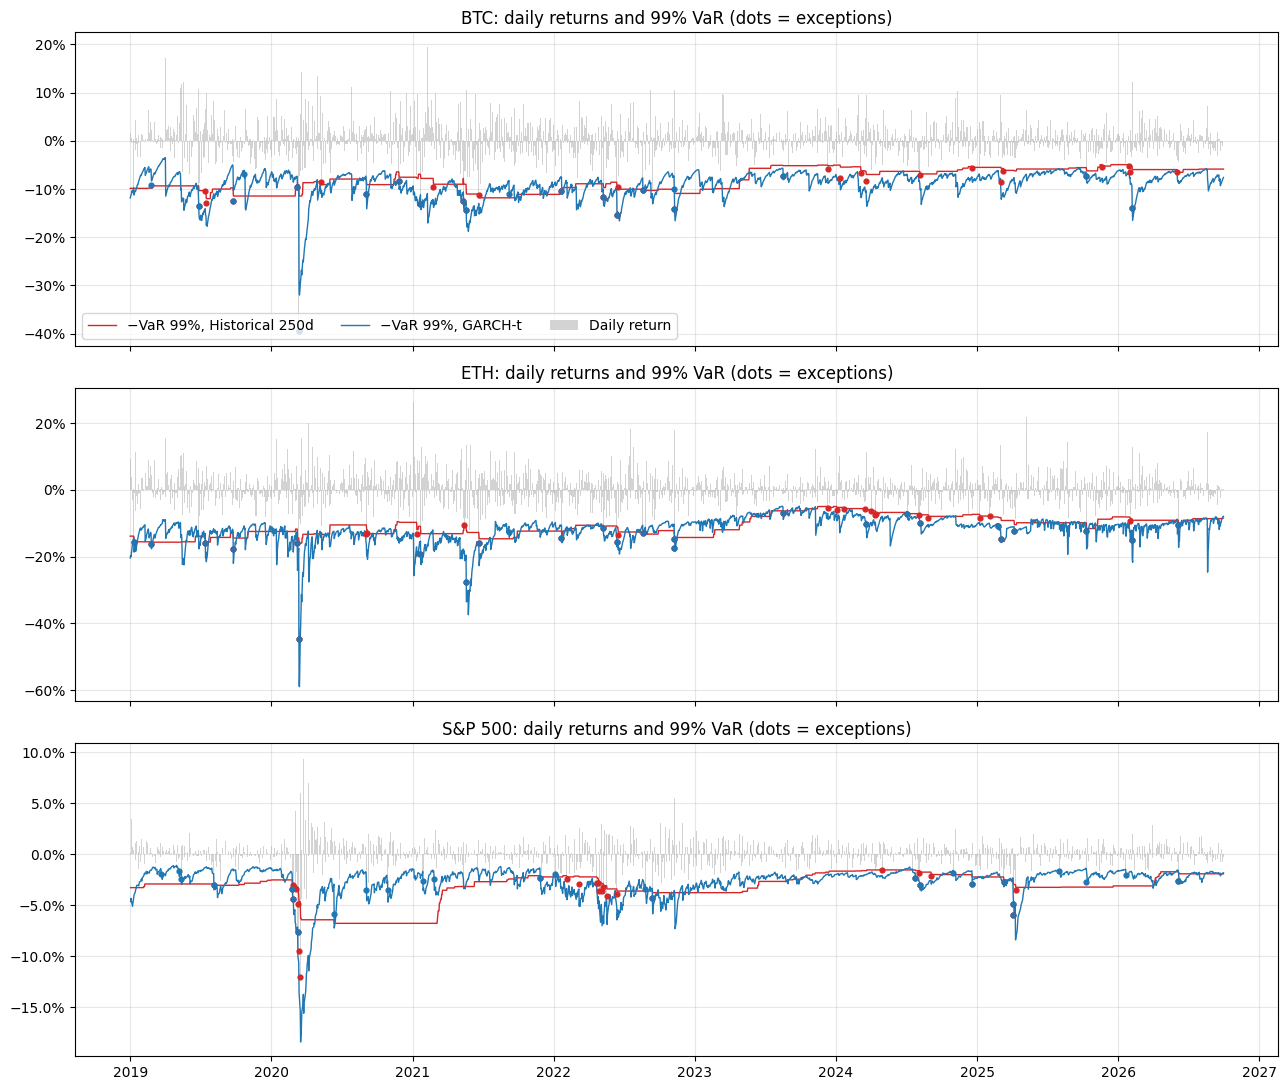

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
for ax, k in zip(axes, forecasts):
    L = loss[k]
    ax.bar(L.index, -L, width=1.5, color="lightgray", label="Daily return")
    for m, color in [("Historical 250d", "tab:red"), ("GARCH-t", "tab:blue")]:
        v = forecasts[k][(m, "VaR99")]
        ax.plot(v.index, -v, color=color, lw=1, label=f"−VaR 99%, {m}")
        exc = L > v
        ax.scatter(L.index[exc], -L[exc], color=color, s=12, zorder=3)
    ax.set_title(f"{k}: daily returns and 99% VaR (dots = exceptions)")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].legend(loc="lower left", ncol=3)
plt.tight_layout()
plt.show()

Historical simulation's VaR is a step function. It moves only when an extreme day enters or leaves the 250-day window. After the March 2020 crash it held the S&P 500's VaR at about −6.5% for a full year, long after volatility had calmed down. In March 2021 the crash left the window and VaR snapped back to about −3%, low enough that the 2022 bear market produced a new cluster of exceptions. GARCH-t jumps immediately after a shock and decays over the following weeks. Neither can anticipate the first day of a crash: on 12 March 2020, both were breached by BTC's −39.5% day.

## 3. Are the exceptions right in number and in timing?

Two classic likelihood-ratio tests, with $n$ days, $x$ exceptions and target rate $\alpha$:

* **Kupiec (1995) proportion of failures.** Is the exception rate $x/n$ consistent with $\alpha$? $\text{LR}_{uc} = -2\ln\frac{(1-\alpha)^{n-x}\alpha^x}{(1-\hat\alpha)^{n-x}\hat\alpha^x} \sim \chi^2_1$.
* **Christoffersen (1998) independence.** Is an exception more likely the day after an exception? The test compares $P(\text{exception}_t \mid \text{exception}_{t-1})$ with $P(\text{exception}_t \mid \text{none}_{t-1})$. A good model's exceptions should arrive independently; clusters mean the model is slow to recognise a high-risk period. $\text{LR}_{ind} \sim \chi^2_1$.
* **Conditional coverage** $\text{LR}_{cc} = \text{LR}_{uc} + \text{LR}_{ind} \sim \chi^2_2$ tests both together.

P-values below 5% are shaded red. "Back-to-back" counts pairs of exceptions on consecutive days.

In [5]:
def kupiec(exc, p):
    """Proportion-of-failures LR test (Kupiec, 1995): is the exception rate equal to p?"""
    n, x = len(exc), int(exc.sum())
    ph = x / n
    lr = -2 * (xlogy(n - x, 1 - p) + xlogy(x, p) - xlogy(n - x, 1 - ph) - xlogy(x, ph))
    return lr, stats.chi2.sf(lr, 1)


def christoffersen(exc):
    """Independence LR test (Christoffersen, 1998): does an exception today change tomorrow's probability?"""
    e = exc.astype(int)
    prev, curr = e[:-1], e[1:]
    n00 = np.sum((prev == 0) & (curr == 0)); n01 = np.sum((prev == 0) & (curr == 1))
    n10 = np.sum((prev == 1) & (curr == 0)); n11 = np.sum((prev == 1) & (curr == 1))
    p01 = n01 / max(n00 + n01, 1); p11 = n11 / max(n10 + n11, 1); p1 = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll_alt = xlogy(n00, 1 - p01) + xlogy(n01, p01) + xlogy(n10, 1 - p11) + xlogy(n11, p11)
    ll_null = xlogy(n00 + n10, 1 - p1) + xlogy(n01 + n11, p1)
    lr = -2 * (ll_null - ll_alt)
    return lr, stats.chi2.sf(lr, 1), n11


rows = []
for k in forecasts:
    for m in MODELS:
        for lvl in BT_LEVELS:
            col = vcol(lvl)
            exc = (loss[k] > forecasts[k][(m, col)]).values
            lr_uc, p_uc = kupiec(exc, lvl)
            lr_ind, p_ind, n11 = christoffersen(exc)
            rows.append({"Asset": k, "Model": m, "Level": col, "Days": len(exc), "Expected": lvl * len(exc),
                         "Exceptions": int(exc.sum()), "Rate": exc.mean(), "Back-to-back": n11,
                         "Kupiec p": p_uc, "Indep. p": p_ind, "Cond. coverage p": stats.chi2.sf(lr_uc + lr_ind, 2)})
bt = pd.DataFrame(rows).set_index(["Asset", "Level", "Model"]).sort_index(level=[0, 1], sort_remaining=False)


def pass_fail(v):
    return "background-color: #f4c7c3" if v < 0.05 else ""


display(bt.style.format({"Expected": "{:.1f}", "Rate": "{:.2%}", "Kupiec p": "{:.3f}", "Indep. p": "{:.3f}",
                         "Cond. coverage p": "{:.3f}"})
        .map(pass_fail, subset=["Kupiec p", "Indep. p", "Cond. coverage p"]))

The exception rates side by side (target: 5% and 1%), and the number of rejections by the conditional coverage test:

In [6]:
summary = (bt.assign(Reject=lambda d: d["Cond. coverage p"] < 0.05)
           .reset_index().pivot_table(index="Model", columns=["Level", "Asset"], values="Rate").loc[MODELS])
display(summary.style.format("{:.2%}").background_gradient(axis=None, cmap="RdYlGn_r", vmin=0, vmax=0.08))
rej = bt.reset_index().assign(Reject=lambda d: d["Cond. coverage p"] < 0.05).groupby("Model")["Reject"].sum().loc[MODELS]
print("Number of rejections by the conditional coverage test (out of 6 asset × level combinations):")
print(rej.to_string())

Number of rejections by the conditional coverage test (out of 6 asset × level combinations):
Model
Historical 250d    4
Normal 250d        6
EWMA normal        3
Filtered HS        1
GARCH-t            2


The table separates the models clearly:

* **The normal models fail at 99%.** Normal 250d and EWMA normal are breached on 1.6–2.4% of days at 99% VaR, which is 1.5–2.4 times the target for all three assets. Every one of these six cases is rejected by Kupiec. At 95%, though, the EWMA normal model is acceptable (4.6–5.8%). This is the fat-tails problem from Module 2 in its purest form. A normal distribution can match the middle of the return distribution but not the far tail.
* **Slow volatility leads to clustered exceptions.** Historical simulation gets the overall rate about right for BTC (1.24%), but on the S&P 500 it has 31 exceptions instead of 19.5, four of them back-to-back, and independence is rejected (p = 0.001). Berkowitz & O'Brien (2002) found the same pattern in banks' own VaR models.
* **Filtered historical simulation is the only model that passes almost everything.** Its 99% exception rate is 1.18–1.24% on all three assets, and only one of six conditional-coverage tests rejects it: ETH at 95%, for clustering. Combining a reactive volatility with the empirical shape of standardized returns handles both problems.
* **GARCH-t is close behind but is not perfectly calibrated.** It is conservative at 99% for crypto (0.74% for BTC) but too aggressive at 95% for the S&P 500 (6.4%, rejected). A single Student-t shape cannot fit both the 95% and the 99% quantile of every asset.

## 4. The Basel traffic light

Regulators look at the last 250 days. Under the 1996 Basel framework, the number of 99% VaR exceptions puts a bank's model into a zone. The zone boundaries come from the binomial distribution: green while the count is consistent with a correct model at 95% confidence, red when a correct model would produce that many exceptions with less than 0.01% probability. A red-zone model must be fixed, and in the yellow zone capital is increased. Below, the zones are recomputed from the binomial distribution and the test is applied every day.

Green zone: 0–4 exceptions, yellow: 5–9, red: 10+ (cumulative probabilities 0.8922, 0.9997, 0.999946)


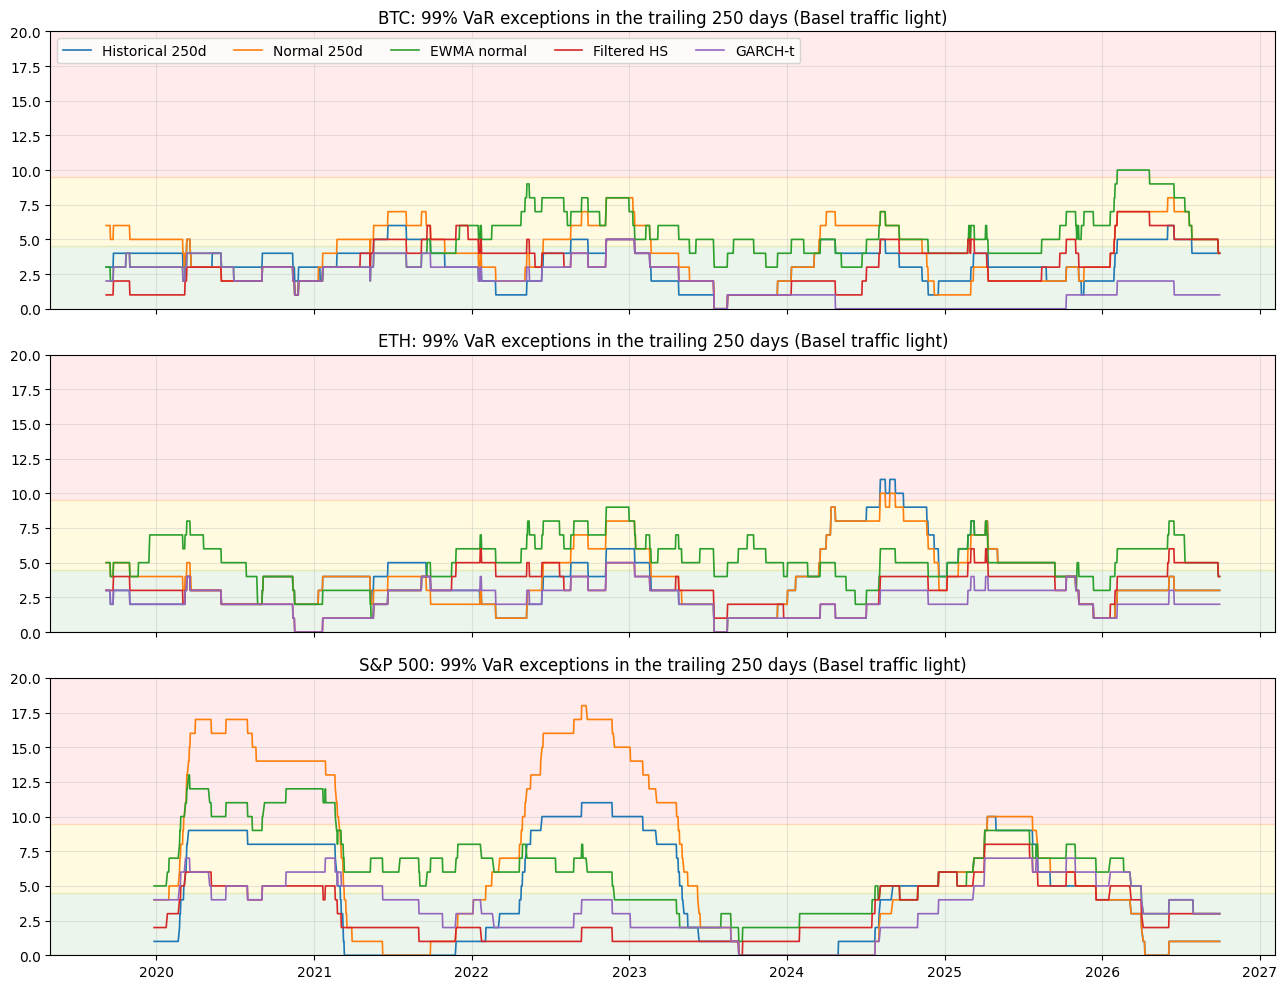

In [7]:
# Basel traffic light for 250 days at 99%: zones from the binomial distribution of the exception count
N_TL = 250
cdf = stats.binom.cdf(np.arange(N_TL + 1), N_TL, 0.01)
green_max = int(np.argmax(cdf >= 0.95)) - 1
red_min = int(np.argmax(cdf >= 0.9999))
print(f"Green zone: 0–{green_max} exceptions, yellow: {green_max + 1}–{red_min - 1}, red: {red_min}+ "
      f"(cumulative probabilities {cdf[green_max]:.4f}, {cdf[red_min - 1]:.4f}, {cdf[red_min]:.6f})")

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
zone_rows = []
for ax, k in zip(axes, forecasts):
    for m in MODELS:
        exc = (loss[k] > forecasts[k][(m, "VaR99")]).astype(int)
        roll = exc.rolling(N_TL).sum().dropna()
        ax.plot(roll.index, roll, lw=1.2, label=m)
        zone_rows.append({"Asset": k, "Model": m, "Green": (roll <= green_max).mean(),
                          "Yellow": ((roll > green_max) & (roll < red_min)).mean(), "Red": (roll >= red_min).mean(),
                          "Max exceptions in 250 days": int(roll.max())})
    ax.axhspan(0, green_max + 0.5, color="green", alpha=0.08)
    ax.axhspan(green_max + 0.5, red_min - 0.5, color="gold", alpha=0.12)
    ax.axhspan(red_min - 0.5, 40, color="red", alpha=0.08)
    ax.set_ylim(0, 20)
    ax.set_title(f"{k}: 99% VaR exceptions in the trailing 250 days (Basel traffic light)")
axes[0].legend(ncol=5, loc="upper left")
plt.tight_layout()
plt.show()
zones = pd.DataFrame(zone_rows).set_index(["Asset", "Model"])
display(zones.style.format({"Green": "{:.0%}", "Yellow": "{:.0%}", "Red": "{:.0%}"})
        .background_gradient(subset=["Red"], cmap="Reds", vmin=0, vmax=1))

The binomial calculation reproduces Basel's table: green for 0–4 exceptions, yellow for 5–9, and red for 10 or more.

The S&P 500 shows the regulatory impact. The **normal 250-day model was in the red zone 33% of the time**, with up to 18 exceptions in a 250-day window after both the COVID crash and the 2022 bear market. Historical simulation was red 10% of the time and EWMA normal 14%. **Filtered HS and GARCH-t never entered the red zone for any asset.** For crypto, the models were rarely red, because crypto's high volatility is already in the 250-day estimates. ETH's historical simulation did reach the red zone in mid-2024, though, with up to 11 exceptions after a calm 2023 had made its window unusually quiet.

## 5. Crisis episodes

Now the 99% VaR exceptions inside six stress episodes. With a correct model, a 50-day episode should produce about 0.5 exceptions. The episodes are chosen in advance from known market events, not from the exceptions themselves.

In [8]:
EPISODES = {
    "COVID crash (2020-02-20 → 2020-04-30)": ("2020-02-20", "2020-04-30"),
    "Crypto May 2021 (2021-05-01 → 2021-06-30)": ("2021-05-01", "2021-06-30"),
    "LUNA / 3AC (2022-05-01 → 2022-06-30)": ("2022-05-01", "2022-06-30"),
    "FTX (2022-11-01 → 2022-11-30)": ("2022-11-01", "2022-11-30"),
    "Yen carry unwind (2024-07-25 → 2024-08-31)": ("2024-07-25", "2024-08-31"),
    "Tariff shock (2025-03-25 → 2025-04-30)": ("2025-03-25", "2025-04-30"),
}
rows = []
for name, (a, b) in EPISODES.items():
    for k in forecasts:
        L = loss[k].loc[a:b]
        row = {"Episode": name, "Asset": k, "Days": len(L), "Worst day": -L.max()}
        for m in MODELS:
            row[m] = int((L > forecasts[k][(m, "VaR99")].loc[a:b]).sum())
        rows.append(row)
crises = pd.DataFrame(rows).set_index(["Episode", "Asset"])
display(crises.style.format({"Worst day": "{:.1%}"})
        .background_gradient(subset=MODELS, cmap="Reds", vmin=0, vmax=6))

* **COVID crash, S&P 500.** In 50 trading days the normal 250-day model was breached **12 times**, historical simulation 8 times and EWMA normal 6 times; Filtered HS and GARCH-t were breached 3 times each. Even the best models had six times their expected count, but the slow 250-day models were 16–24 times off.
* **COVID crash, crypto.** Every model was breached exactly twice: on 8 March 2020 (BTC −9.6%, ETH −15.9%) and on 12 March, when BTC fell 39.5% and ETH 44.6% in one day. These were jumps out of a calm market, and no model based on past volatility can foresee them. After those two days, the reactive models held.
* **2022 (LUNA and FTX).** The crypto collapses did not break the reactive models (2 exceptions each), but the S&P 500's 2022 bear market cost the normal model 6 exceptions during May–June 2022 alone, while Filtered HS and GARCH-t had none.
* **2024–2025 shocks** (the August 2024 yen carry unwind, the April 2025 tariff shock) produced 0–3 exceptions per model. These were shorter episodes, and the reactive models adapted within days.

The day-by-day view of March 2020 shows *why* the models differ:

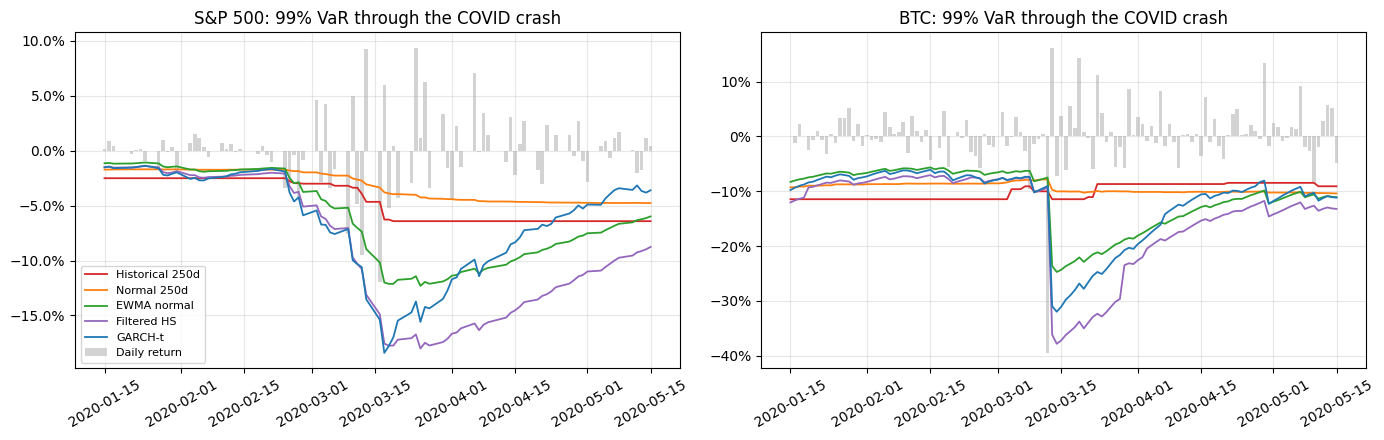

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, k in zip(axes, ["S&P 500", "BTC"]):
    a, b = "2020-01-15", "2020-05-15"
    L = loss[k].loc[a:b]
    ax.bar(L.index, -L, color="lightgray", label="Daily return")
    for m, color in zip(MODELS, ["tab:red", "tab:orange", "tab:green", "tab:purple", "tab:blue"]):
        ax.plot(L.index, -forecasts[k][(m, "VaR99")].loc[a:b], color=color, lw=1.3, label=m)
    ax.set_title(f"{k}: 99% VaR through the COVID crash")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

On the S&P 500, the reactive models (EWMA, Filtered HS, GARCH-t) raised their VaR from about 2% to 12–18% within three weeks as volatility rose. Filtered HS and GARCH-t were breached only once in March, on 9 March. The 250-day models moved late and little: historical simulation reached 6.5% and the normal model 4%, because a few extreme days hardly change a 250-day quantile or standard deviation. Historical simulation was breached five times in March, the last on 16 March (−12.0%). For BTC, all models were blindsided by the single −39.5% day. After it, the reactive models jumped to a VaR of 25–38%, while historical simulation stayed near 10%.

## 6. Expected shortfall: are the tail losses the right size?

VaR says how often a loss is exceeded, but not by how much. Basel's Fundamental Review of the Trading Book (FRTB) replaced 99% VaR with **97.5% expected shortfall**, the average loss on the worst 2.5% of days. Following McNeil & Frey (2000), on the days when the loss exceeds a model's 97.5% VaR, the actual loss should on average equal the model's ES. The standardized residuals $(L_t - \text{ES}_t)/\sigma_t$ should then have mean zero. A positive mean (one-sided p-value below 5%) means the model underestimates tail losses.

In [10]:
# McNeil-Frey check of 97.5% ES: on days when the loss exceeds the model's 97.5% VaR,
# the loss should equal the model's ES on average, so the standardized residuals (loss − ES) / σ should have mean zero.
rows = []
for k in forecasts:
    L = loss[k]
    for m in MODELS:
        f = forecasts[k][m]
        tail = L > f["VaR97.5"]
        resid = (L[tail] - f["ES97.5"][tail]) / f["sigma"][tail]
        tstat = resid.mean() / (resid.std(ddof=1) / np.sqrt(len(resid)))
        rows.append({"Asset": k, "Model": m, "Tail days": int(tail.sum()), "Expected tail days": ES_LEVEL * len(L),
                     "Mean loss / ES": (L[tail] / f["ES97.5"][tail]).mean(),
                     "Residual t": tstat, "p (ES too small)": stats.t.sf(tstat, len(resid) - 1)})
es_tab = pd.DataFrame(rows).set_index(["Asset", "Model"])
display(es_tab.style.format({"Expected tail days": "{:.0f}", "Mean loss / ES": "{:.2f}", "Residual t": "{:.2f}",
                             "p (ES too small)": "{:.3f}"}).map(pass_fail, subset=["p (ES too small)"]))

* **The normal models underestimate tail losses by 19–32%** (mean loss / ES of 1.19–1.32) for every asset, all with p ≤ 0.001. A normal ES is wrong twice: it is breached too often, and when it is breached the loss is too large.
* **Historical simulation's ES is about right for crypto (1.05) but 14% too small for the S&P 500** (p = 0.009). When equity volatility jumps, an equally weighted 250-day window reacts too slowly to its size as well as its frequency.
* **Filtered HS gets the size right for all three assets** (1.01–1.04, no rejections).
* **GARCH-t errs on the conservative side** for ETH (0.89: the realized tail losses were 11% *smaller* than its ES). The fitted Student-t has heavier tails than ETH actually showed.

## 7. Takeaways

1. **Normal VaR fails where it matters.** At 99%, normal and EWMA-normal models were breached 1.5–2.4 times too often for all three assets, and their ES was 19–32% too small. They pass at 95%, which is why the failure is easy to miss.
2. **Slow models fail in crises and stay wrong afterwards.** Equal-weighted 250-day models produce exceptions in clusters: 12 S&P 500 exceptions for the normal model in 50 days of the COVID crash, and a red Basel zone for a third of the period. Then they carry the crisis volatility for a year after it has passed.
3. **Combining reactive volatility with fat tails works.** Filtered historical simulation (EWMA volatility with empirical standardized quantiles) was the only model with correct 99% coverage, independent exceptions and correctly sized ES on all three assets, and it never entered the red zone.
4. **No model can see a jump coming from a calm market.** All five models were breached on 8 and 12 March 2020 in crypto. VaR models are forecasts of volatility, not of crashes. Stress tests and position limits have to cover what VaR cannot.
5. **Model risk is asymmetric across assets.** The same GARCH-t model was too conservative for crypto at 99% and too aggressive for equities at 95%. A risk model has to be backtested on every asset and at every level where it is used.

**Next steps:** add a GARCH model with skewed-t errors and asymmetric volatility (GJR), test multi-day horizons with overlapping returns, backtest a portfolio of the three assets where correlation matters, and apply the Acerbi–Székely (2014) ES tests with simulated critical values.

## References

* Kupiec, P. H. (1995). Techniques for Verifying the Accuracy of Risk Measurement Models. *Journal of Derivatives* 3(2), 73–84.
* Basel Committee on Banking Supervision (1996). *Supervisory Framework for the Use of "Backtesting" in Conjunction with the Internal Models Approach to Market Risk Capital Requirements.* BIS.
* J.P. Morgan / Reuters (1996). *RiskMetrics — Technical Document*, 4th ed.
* Bollerslev, T. (1987). A Conditionally Heteroskedastic Time Series Model for Speculative Prices and Rates of Return. *Review of Economics and Statistics* 69(3), 542–547.
* Christoffersen, P. F. (1998). Evaluating Interval Forecasts. *International Economic Review* 39(4), 841–862.
* Hull, J., White, A. (1998). Incorporating Volatility Updating into the Historical Simulation Method for Value-at-Risk. *Journal of Risk* 1(1), 5–19.
* Barone-Adesi, G., Giannopoulos, K., Vosper, L. (1999). VaR without Correlations for Portfolios of Derivative Securities. *Journal of Futures Markets* 19(5), 583–602.
* McNeil, A. J., Frey, R. (2000). Estimation of Tail-Related Risk Measures for Heteroscedastic Financial Time Series: An Extreme Value Approach. *Journal of Empirical Finance* 7(3–4), 271–300.
* Berkowitz, J., O'Brien, J. (2002). How Accurate Are Value-at-Risk Models at Commercial Banks? *Journal of Finance* 57(3), 1093–1111.
* Pritsker, M. (2006). The Hidden Dangers of Historical Simulation. *Journal of Banking & Finance* 30(2), 561–582.
* Acerbi, C., Székely, B. (2014). Back-testing Expected Shortfall. *Risk*, December.